# LoomIQ 03 · Feature Engineering

Turn the cleaned data into model-ready inputs **without leaking the answer**.

The reusable code is in `src/loomiq/features/build_features.py`. This notebook shows each step and explains the choices.

## Goals

1. Create the target `met_target` (and `productivity_gap` for analysis only)
2. Add per-worker features so big and small teams compare fairly
3. Decide which columns are **not** model inputs, and why
4. Encode categorical columns, identically for training and for live predictions
5. Save the feature table to `data/processed/`

In [1]:
# Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from loomiq.config import load_config
from loomiq.data.clean import load_clean_productivity
from loomiq.features import build_features as bf
from loomiq.utils.plotting import DEPARTMENT_COLORS, apply_style, save_figure

config = load_config()
apply_style()
pd.set_option("display.max_columns", 50)

df = load_clean_productivity()
df.shape

(1197, 16)

## 1. The target: `met_target`

A team-day **meets its target** when `actual_productivity >= targeted_productivity`. Landing exactly on target counts as met.

`productivity_gap` (actual minus target) is kept for analysis, but it is **never a model input**: it is the answer written another way.

In [2]:
table = bf.add_target(df)
table[["targeted_productivity", "actual_productivity", "productivity_gap", "met_target"]].head()

,targeted_productivity,actual_productivity,productivity_gap,met_target
0,0.80,0.940725,0.140725,1
1,0.75,0.886500,0.136500,1
2,0.80,0.800570,0.000570,1
3,0.80,0.800570,0.000570,1
4,0.80,0.800382,0.000382,1


In [3]:
counts = table["met_target"].value_counts().rename({1: "met", 0: "missed"})
pd.DataFrame({"rows": counts, "share": (counts / len(table)).round(3)})

,rows,share
met_target,,
met,874,0.73
missed,323,0.27


874 met (73%) and 323 missed (27%). The model's real job is to find the **missed** days, so notebook 04 judges models by F1 on that class.

## 2. Per-worker features

Team sizes range from 2 to 89 people, and finishing teams are much smaller than sewing teams. A raw total like 960 overtime minutes means something very different for 8 people than for 58.

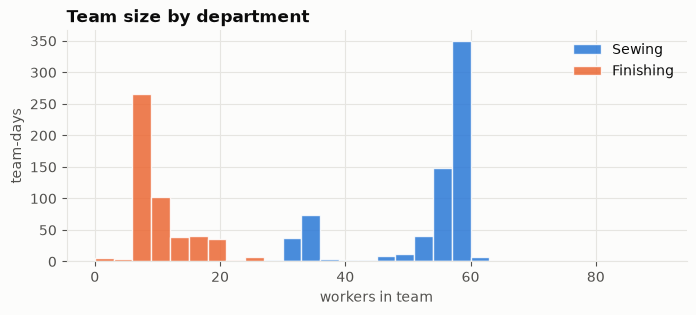

In [4]:
fig, ax = plt.subplots(figsize=(8, 3))
for dept in ["sewing", "finishing"]:
    sizes = df.loc[df["department"] == dept, "no_of_workers"]
    ax.hist(sizes, bins=np.arange(0, 92, 3), color=DEPARTMENT_COLORS[dept], alpha=0.85,
            label=dept.title(), edgecolor="white", linewidth=1)
ax.set_xlabel("workers in team")
ax.set_ylabel("team-days")
ax.legend()
ax.set_title("Team size by department")
save_figure(fig, "fe_01_team_size")
plt.show()

In [5]:
table = bf.add_per_worker_features(table)
per_worker = ["overtime_per_worker", "wip_per_worker", "idle_ratio", "incentive_per_worker"]
table.groupby("department", observed=True)[["over_time", "overtime_per_worker", "wip", "wip_per_worker"]].median()

,over_time,overtime_per_worker,wip,wip_per_worker
department,,,,
sewing,6840.0,120.0,1039.0,19.719298
finishing,1440.0,120.0,0.0,0.000000


Totals differ hugely between departments (median overtime 6,840 vs 1,440 minutes), but per worker it is **identical: 120 minutes (2 hours) each**. The raw total mostly measures team size, not effort. Per-worker values describe **how hard each person works**, which is what affects productivity.

| New feature | Formula | Meaning |
|---|---|---|
| `overtime_per_worker` | over_time / no_of_workers | overtime minutes per person |
| `wip_per_worker` | wip / no_of_workers | backlog per person |
| `idle_ratio` | idle_men / no_of_workers | share of the team standing idle |
| `incentive_per_worker` | incentive / no_of_workers | bonus per person (only used if incentive is switched on) |

A team size of 0 never occurs, but the code guards against division by zero anyway, so live data can't produce infinite values.

## 3. What is *not* a model input, and why

In [6]:
print("wip_missing identical to department == finishing:",
      (df["wip_missing"] == (df["department"] == "finishing")).all())

wip_missing identical to department == finishing: True


| Column | Why it is left out |
|---|---|
| `actual_productivity`, `productivity_gap` | **Leakage**: they contain the answer |
| `incentive`, `incentive_per_worker` | **Possible leakage**: notebook 02 showed incentive may be paid *because* a team hit its target. Off by default (`use_incentive: false` in config); notebook 04 compares both ways |
| `date` | Only 10 weeks of data, so the model would memorize dates instead of learning patterns |
| `wip_missing` | Exactly the same as `department == finishing` (checked above), so it adds nothing |

`build_features` also checks for leakage columns and **raises an error** if any slip into the inputs.

## 4. Encoding categories

`department`, `day`, `quarter` and `team` are one-hot encoded (one 0/1 column per value, minus the first value, which is the "all zeros" case).

The category lists are **fixed** (e.g. teams 1 to 12), so a single live line produces exactly the same columns as the full training data. Without this, a row from team 7 would only create a `team_7` column and the model would break.

In [7]:
X, y = bf.build_features(df)
print("X:", X.shape, "| y:", y.shape)
X.columns.tolist()

X: (1197, 31) | y: (1197,)


['targeted_productivity',
 'smv',
 'wip',
 'over_time',
 'idle_time',
 'idle_men',
 'no_of_style_change',
 'no_of_workers',
 'overtime_per_worker',
 'wip_per_worker',
 'idle_ratio',
 'department_finishing',
 'day_Sunday',
 'day_Monday',
 'day_Tuesday',
 'day_Wednesday',
 'day_Thursday',
 'quarter_Quarter2',
 'quarter_Quarter3',
 'quarter_Quarter4',
 'team_2',
 'team_3',
 'team_4',
 'team_5',
 'team_6',
 'team_7',
 'team_8',
 'team_9',
 'team_10',
 'team_11',
 'team_12']

In [8]:
# One live line, without the answer column: same 31 columns, y is None
one_line = df.iloc[[100]].drop(columns="actual_productivity")
X_one, y_one = bf.build_features(one_line)
print("Same columns as training:", list(X_one.columns) == list(X.columns), "| y:", y_one)
X_one.loc[:, (X_one != 0).any()]

Same columns as training: True | y: None


,targeted_productivity,smv,wip,over_time,no_of_workers,overtime_per_worker,wip_per_worker,day_Tuesday,team_11
100,0.75,19.31,590.0,9900.0,55.0,180.0,10.727273,1.0,1.0


## 5. Save the feature table

The saved table stays **readable** (no one-hot columns), so it is easy to inspect. Encoding happens when the model is trained or used.

In [9]:
table = bf.build_feature_table(df)
path = bf.save_feature_table(table)
print("Saved", path.name, table.shape)
table.head(3)

2026-10-30 19:32:07 | INFO     | loomiq.features.build_features | Saved feature table (1197 rows, 22 columns) to D:\Projects\LoomIQ\LoomIQ-Garment-Factory-Intelligence-Platform\data\processed\productivity_features.csv


Saved productivity_features.csv (1197, 22)


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity,wip_missing,productivity_gap,met_target,overtime_per_worker,incentive_per_worker,wip_per_worker,idle_ratio
0,2015-01-01,Quarter1,sewing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725,False,0.140725,1,120.0,1.661017,18.779661,0.0
1,2015-01-01,Quarter1,finishing,Thursday,1,0.75,3.94,0.0,960,0,0.0,0,0,8.0,0.886500,True,0.136500,1,120.0,0.000000,0.000000,0.0
2,2015-01-01,Quarter1,sewing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570,False,0.000570,1,120.0,1.639344,31.737705,0.0


## Summary

**Model inputs (31 columns):**
- 11 numeric: target level, SMV, WIP, overtime, idle time, idle workers, style changes, team size, and the three per-worker features
- 20 one-hot: department (1), day (5), week of month (3), team (11)

**Target:** `met_target` (1 = met, 0 = missed), 73% / 27%.

**Left out on purpose:** the answer columns, incentive (by default), date, and `wip_missing`.

**Next:** notebook 04 trains and compares the models.